<a href="https://colab.research.google.com/github/sokrypton/ColabFold/blob/main/ESMFold.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**ESMFold**
for more details see: [Github](https://github.com/facebookresearch/esm/tree/main/esm), [Preprint](https://www.biorxiv.org/content/10.1101/2022.07.20.500902v1)

#### **Tips and Instructions**
- click the little ▶ play icon to the left of each cell below.
- use "/" to specify chainbreaks, (eg. sequence="AAA/AAA")
- for homo-oligomeric predictions, set copies > 1
- See [experimental notebook](https://colab.research.google.com/github/sokrypton/ColabFold/blob/main/beta/ESMFold_advanced.ipynb) for more advanced options (like sampling).

#### **Colab Limitations**
- For short monomeric proteins under the length 400, consider using [ESMFold API](https://esmatlas.com/resources?action=fold) (no need for GPU, super fast!)
- On Tesla T4 (typical free colab GPU), max total length ~ 900

In [1]:
#@title Install ESMFold dependencies (repaired)
# Run this notebook in its own Colab GPU runtime.
import os
import sys
import site
import gc
import json
import shutil
import subprocess
import threading
import signal
import importlib
import importlib.metadata
import hashlib
from pathlib import Path
from collections import deque
from urllib.request import urlopen, Request

version = "1" #@param ["0", "1"]
weights_dir = Path("/content/esmfold_weights")
weights_dir.mkdir(parents=True, exist_ok=True)
model_name = str(weights_dir / f"esmfold_3B_v{version}.pt")
esm2_weights_path = weights_dir / "esm2_t36_3B_UR50D.pt"
regression_path = weights_dir / "esm2_t36_3B_UR50D-contact-regression.pt"
log_path = Path("/content/esmfold_install.log")
log_path.write_text("")

print("Kernel:", sys.version, "\nExecutable:", sys.executable, flush=True)
pip_executable = shutil.which("pip") or shutil.which("pip3")
if pip_executable is None:
    raise RuntimeError("pip is not available in this Colab runtime.")

def run_logged(command, timeout=1200):
    print("Running:", " ".join(map(str, command)), flush=True)
    tail = deque(maxlen=60)
    timed_out = False
    with log_path.open("a") as log:
        log.write("\nCOMMAND: " + repr(command) + "\n")
        process = subprocess.Popen(
            list(map(str, command)), stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT, text=True, bufsize=1, start_new_session=True,
        )
        def stop_on_timeout():
            nonlocal timed_out
            if process.poll() is None:
                timed_out = True
                try:
                    os.killpg(process.pid, signal.SIGTERM)
                except ProcessLookupError:
                    pass
        timer = threading.Timer(timeout, stop_on_timeout)
        timer.start()
        try:
            for line in process.stdout:
                print(line, end="", flush=True)
                log.write(line)
                tail.append(line)
            return_code = process.wait()
        finally:
            timer.cancel()
        if return_code or timed_out:
            reason = f"Timeout after {timeout} seconds" if timed_out else f"Exit code {return_code}"
            raise RuntimeError(f"{reason}. Full log: {log_path}\n" + "".join(tail))

def pip_install(*requirements, extra=()):
    run_logged([
        pip_executable, "--python", sys.executable, "install", "--break-system-packages",
        *extra, *requirements,
    ])

if shutil.which("aria2c") is None:
    run_logged(["apt-get", "update", "-qq"])
    run_logged(["apt-get", "install", "-y", "aria2", "git", "build-essential"])

pip_install(
    "setuptools<81", "wheel", "ninja", "torch", "numpy", "scipy", "matplotlib",
    "omegaconf", "biopython", "ml-collections", "einops", "py3Dmol", "modelcif", "dm-tree",
)
for package_dir in site.getsitepackages():
    if package_dir not in sys.path:
        site.addsitedir(package_dir)
importlib.invalidate_caches()

run_logged([
    sys.executable, "-c",
    "import torch; from torch.utils.cpp_extension import CUDA_HOME; "
    "print('Torch:', torch.__version__, 'CUDA:', torch.version.cuda, 'CUDA_HOME:', CUDA_HOME); "
    "assert torch.cuda.is_available(), 'Select a GPU runtime in Colab'; "
    "assert CUDA_HOME is not None, 'CUDA compiler toolkit is unavailable'",
])

# Same forks used by the original ColabFold ESMFold notebook, pinned for reproducibility.
OPENFOLD_COMMIT = "5b3e9b800441a6e0543935e31bcf52937aabd189"
ESM_COMMIT = "f6ef2277cd3e2b75ff4e4c8a8efa7457671ddb33"
build_dir = Path("/content/esmfold_sources/openfold")
build_dir.parent.mkdir(parents=True, exist_ok=True)
if not (build_dir / ".git").is_dir():
    run_logged(["git", "clone", "--no-checkout", "https://github.com/sokrypton/openfold.git", build_dir])
run_logged(["git", "-C", build_dir, "checkout", "--detach", OPENFOLD_COMMIT])
setup_path = build_dir / "setup.py"
setup_source = setup_path.read_text()
if "-std=c++17" in setup_source:
    setup_path.write_text(setup_source.replace("-std=c++17", "-std=c++20"))
elif "-std=c++20" not in setup_source:
    raise RuntimeError("Unexpected setup.py: compiler standard flag not found.")
os.environ.setdefault("MAX_JOBS", "2")
pip_install(str(build_dir), extra=("--no-build-isolation", "--no-deps", "-v"))
pip_install(
    f"git+https://github.com/sokrypton/esm.git@{ESM_COMMIT}",
    extra=("--no-build-isolation", "--no-deps"),
)

# Clear imports left by failed installations.
for name in list(sys.modules):
    if name in ("esm", "openfold") or name.startswith(("esm.", "openfold.")):
        del sys.modules[name]
importlib.invalidate_caches()
import openfold
import esm
import torch
# Exact copy of the original OpenStructure resource retained by ColabFold.
resource_url = (
    "https://raw.githubusercontent.com/sokrypton/ColabFold/main/"
    "colabfold/openstructure/stereo_chemical_props.txt"
)
with urlopen(resource_url, timeout=30) as response:
    resource_data = response.read()
if hashlib.sha256(resource_data).hexdigest() != "24510899eeb49167cffedec8fa45363a4d08279c0c637a403b452f7d0ac09451":
    raise RuntimeError("Unexpected stereo_chemical_props.txt checksum.")
resource_path = Path(openfold.__file__).parent / "resources" / "stereo_chemical_props.txt"
resource_path.parent.mkdir(parents=True, exist_ok=True)
resource_path.write_bytes(resource_data)
from esm.esmfold.v1.esmfold import ESMFold

print("ESM:", esm.__file__)
print("OpenFold:", openfold.__file__)
print("Dependencies installed. Next run: Download official Meta checkpoints.")


Kernel: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0] 
Executable: /usr/bin/python3
Running: apt-get update -qq
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Running: apt-get install -y aria2 git build-essential
Reading package lists...
Building dependency tree...
Reading state information...
git is already the newest version (1:2.43.0-1ubuntu7.4).
build-essential is already the newest version (12.10ubuntu1).
The following NEW packages will be installed:
  aria2 libaria2-0 libcares2
0 upgraded, 3 newly installed, 0 to remove and 144 not upgraded.
Need to get 1,566 kB of archives.
After this operation, 5,692 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble-updates/main amd64 libcares2 amd64 1.27.0-1.0ubuntu1.1 [74.2 kB]
Get:2 http://archive.ubuntu.com/ubuntu noble/universe amd64 libaria2-0 amd64 1.37.0+d

In [2]:
#@title Download official Meta checkpoints (~8.45 GB total for v1)
# No background download and no infinite wait. Failures stop this cell.
CHECKPOINT_URLS = {
    Path(model_name).name: f"https://dl.fbaipublicfiles.com/fair-esm/models/esmfold_3B_v{version}.pt",
    esm2_weights_path.name: "https://dl.fbaipublicfiles.com/fair-esm/models/esm2_t36_3B_UR50D.pt",
    regression_path.name: "https://dl.fbaipublicfiles.com/fair-esm/regression/esm2_t36_3B_UR50D-contact-regression.pt",
}
for filename, url in CHECKPOINT_URLS.items():
    print("Checking:", filename, flush=True)
    with urlopen(Request(url, method="HEAD"), timeout=30) as response:
        expected_size = int(response.headers.get("Content-Length", "0"))
        print("HTTP:", response.status, "Expected bytes:", expected_size, flush=True)
    destination = weights_dir / filename
    control_file = Path(str(destination) + ".aria2")
    if expected_size and destination.is_file() and destination.stat().st_size == expected_size and not control_file.exists():
        print("Already downloaded:", filename)
        continue
    run_logged([
        "aria2c", "--continue=true", "--auto-file-renaming=false", "--allow-overwrite=true",
        "--file-allocation=none", "--max-connection-per-server=8", "--split=8",
        "--connect-timeout=20", "--timeout=30", "--max-tries=3", "--retry-wait=5",
        "--summary-interval=10", "--console-log-level=notice",
        "--dir", weights_dir, "--out", filename, url,
    ], timeout=1800)
    if not destination.is_file() or control_file.exists():
        raise RuntimeError(f"Download incomplete: {destination}")
    if expected_size and destination.stat().st_size != expected_size:
        raise RuntimeError(f"File size mismatch: {destination}")
print("All checkpoints downloaded. Next run: run ESMFold.")


Checking: esmfold_3B_v1.pt
HTTP: 200 Expected bytes: 2771653574
Running: aria2c --continue=true --auto-file-renaming=false --allow-overwrite=true --file-allocation=none --max-connection-per-server=8 --split=8 --connect-timeout=20 --timeout=30 --max-tries=3 --retry-wait=5 --summary-interval=10 --console-log-level=notice --dir /content/esmfold_weights --out esmfold_3B_v1.pt https://dl.fbaipublicfiles.com/fair-esm/models/esmfold_3B_v1.pt

11/26 10:08:21 [NOTICE] Downloading 1 item(s)
[#536e1d 302MiB/2.5GiB(11%) CN:8 DL:330MiB ETA:7s]
[#536e1d 438MiB/2.5GiB(16%) CN:8 DL:211MiB ETA:10s]
[#536e1d 441MiB/2.5GiB(16%) CN:8 DL:132MiB ETA:16s]
[#536e1d 677MiB/2.5GiB(25%) CN:8 DL:156MiB ETA:12s]
[#536e1d 756MiB/2.5GiB(28%) CN:8 DL:141MiB ETA:13s]
[#536e1d 773MiB/2.5GiB(29%) CN:8 DL:111MiB ETA:16s]
[#536e1d 0.9GiB/2.5GiB(35%) CN:8 DL:119MiB ETA:14s]
[#536e1d 1.2GiB/2.5GiB(47%) CN:8 DL:141MiB ETA:9s]
 *** Download Progress Summary as of Thu Nov 26 10:08:31 2026 *** 
[#536e1d 1.3GiB/2.5GiB(53%) CN:8 

In [5]:
#@title Checkpoint loader for official Meta files
# Only changes loading and memory allocation; keeps the original ESMFold architecture.
# Files come exclusively from the official Meta URLs in the preceding cell.
from unittest.mock import patch

# Release the model retained by the previous loader-error traceback, if any.
# Clear only frames from this loader, preserving notebook globals and downloads.
def _release_previous_loader_failure():
    import sys
    import gc
    import torch
    last_error = getattr(sys, "last_exc", None) or getattr(sys, "last_value", None)
    tb = getattr(sys, "last_traceback", None) or getattr(last_error, "__traceback__", None)
    while tb is not None:
        if tb.tb_frame.f_code.co_name == "load_esmfold_official":
            tb.tb_frame.clear()
        tb = tb.tb_next
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

_release_previous_loader_failure()
del _release_previous_loader_failure

def load_esmfold_official(checkpoint_path):
    import esm
    import torch
    import gc
    from esm.esmfold.v1.esmfold import ESMFold

    def load_language_model():
        checkpoint = torch.load(
            str(esm2_weights_path), map_location="cpu", mmap=True, weights_only=False,
        )
        regression = torch.load(
            str(regression_path), map_location="cpu", weights_only=False,
        )
        checkpoint["model"].update(regression["model"])
        # Do not allocate a second randomly initialized 3B-parameter language model.
        with torch.device("meta"):
            language_model, alphabet, state = esm.pretrained._load_model_and_alphabet_core_v2(checkpoint)
        language_model.load_state_dict(state, strict=True, assign=True)
        remaining_meta = [
            name for name, value in list(language_model.named_parameters()) + list(language_model.named_buffers())
            if value.is_meta
        ]
        if remaining_meta:
            raise RuntimeError(f"Language model tensors remain uninitialized: {remaining_meta}")
        language_model.half().requires_grad_(False)
        del checkpoint, regression, state
        gc.collect()
        return language_model, alphabet

    checkpoint = torch.load(
        str(checkpoint_path), map_location="cpu", mmap=True, weights_only=False,
    )
    cfg = checkpoint["cfg"]["model"]
    state = checkpoint["model"]
    with patch("esm.pretrained.esm2_t36_3B_UR50D", side_effect=load_language_model):
        folded_model = ESMFold(esmfold_config=cfg)
    folded_model.eval().requires_grad_(False)
    folded_model = folded_model.cuda()
    incompatible = folded_model.load_state_dict(state, strict=False)
    missing = [key for key in incompatible.missing_keys if not key.startswith("esm.")]
    # These historical non-trainable buffers are absent from the current
    # state_dict. The four residue-geometry buffers are rebuilt on first use.
    allowed_legacy_buffers = {
        "positional_encoding._float_tensor",
        "trunk.structure_module.default_frames",
        "trunk.structure_module.group_idx",
        "trunk.structure_module.atom_mask",
        "trunk.structure_module.lit_positions",
    }
    unexpected = [key for key in incompatible.unexpected_keys if key not in allowed_legacy_buffers]
    if missing or unexpected:
        message = f"Checkpoint mismatch: missing={missing}, unexpected={unexpected}"
        del folded_model, checkpoint, state
        gc.collect()
        torch.cuda.empty_cache()
        raise RuntimeError(message)
    ignored_buffers = sorted(set(incompatible.unexpected_keys) & allowed_legacy_buffers)
    if ignored_buffers:
        print("Ignored legacy non-trainable checkpoint buffers:", ignored_buffers, flush=True)
    folded_model._checkpoint_ignored_buffers = tuple(ignored_buffers)
    del checkpoint, state
    gc.collect()
    torch.cuda.empty_cache()
    return folded_model

print("Official checkpoint loader ready.")

Official checkpoint loader ready.


In [6]:
#@title ##run **ESMFold**
%%time
from string import ascii_uppercase, ascii_lowercase
import hashlib, re, os
import numpy as np
import torch
from torch.utils._pytree import tree_map
import matplotlib.pyplot as plt
from scipy.special import softmax
import gc

def parse_output(output):
  pae = (output["aligned_confidence_probs"][0] * np.arange(64)).mean(-1) * 31
  plddt = output["plddt"][0,:,1]

  bins = np.append(0,np.linspace(2.3125,21.6875,63))
  sm_contacts = softmax(output["distogram_logits"],-1)[0]
  sm_contacts = sm_contacts[...,bins<8].sum(-1)
  xyz = output["positions"][-1,0,:,1]
  mask = output["atom37_atom_exists"][0,:,1] == 1
  o = {"pae":pae[mask,:][:,mask],
       "plddt":plddt[mask],
       "sm_contacts":sm_contacts[mask,:][:,mask],
       "xyz":xyz[mask]}
  return o

def get_hash(x): return hashlib.sha1(x.encode()).hexdigest()
alphabet_list = list(ascii_uppercase+ascii_lowercase)

jobname = "esmfold_task5" #@param {type:"string"}
jobname = re.sub(r'\W+', '', jobname)[:50]

sequence = "MLLLLLLLLLLPPLVLRVAASRCLHDETQKSVSLLRPPFSQLPSKSRSSSLTLPSSRDPQPLRIQSCYLGDHISDGAWDPEGEGMRGGSRALAAVREATQ" #@param {type:"string"}
sequence = re.sub("[^A-Z:]", "", sequence.replace("/",":").upper())
sequence = re.sub(":+",":",sequence)
sequence = re.sub("^[:]+","",sequence)
sequence = re.sub("[:]+$","",sequence)
copies = 1 #@param {type:"integer"}
if copies == "" or copies <= 0: copies = 1
sequence = ":".join([sequence] * copies)
num_recycles = 3 #@param ["0", "1", "2", "3", "6", "12", "24"] {type:"raw"}
chain_linker = 25

ID = jobname+"_"+get_hash(sequence)[:5]
seqs = sequence.split(":")
lengths = [len(s) for s in seqs]
length = sum(lengths)
print("length",length)

u_seqs = list(set(seqs))
if len(seqs) == 1: mode = "mono"
elif len(u_seqs) == 1: mode = "homo"
else: mode = "hetero"

if "model" not in dir() or model_name != model_name_:
  if "model" in dir():
    # delete old model from memory
    del model
    gc.collect()
    if torch.cuda.is_available():
      torch.cuda.empty_cache()

  model = load_esmfold_official(model_name)
  model.eval().cuda().requires_grad_(False)
  model_name_ = model_name

# optimized for Tesla T4
if length > 700:
  model.set_chunk_size(64)
else:
  model.set_chunk_size(128)

torch.cuda.empty_cache()
output = model.infer(sequence,
                     num_recycles=num_recycles,
                     chain_linker="X"*chain_linker,
                     residue_index_offset=512)

pdb_str = model.output_to_pdb(output)[0]
output = tree_map(lambda x: x.cpu().numpy(), output)
ptm = output["ptm"][0]
plddt = output["plddt"][0,...,1].mean()
O = parse_output(output)
print(f'ptm: {ptm:.3f} plddt: {plddt:.3f}')
Path(ID).mkdir(parents=True, exist_ok=True)
prefix = f"{ID}/ptm{ptm:.3f}_r{num_recycles}_default"
np.savetxt(f"{prefix}.pae.txt",O["pae"],"%.3f")
with open(f"{prefix}.pdb","w") as out:
  out.write(pdb_str)
# Record input and actual settings for the assignment.
from datetime import datetime, timezone
Path(ID, "sequence.fasta").write_text(f">protein_task\n{sequence}\n")
metadata = {
    "predictor": "ESMFold", "version": version, "sequence": sequence,
    "num_recycles": num_recycles, "copies": copies, "ptm": float(ptm),
    "mean_plddt": float(plddt), "torch": torch.__version__,
    "python": sys.version, "cuda": torch.version.cuda,
    "openfold_commit": OPENFOLD_COMMIT, "esm_commit": ESM_COMMIT,
    "checkpoint_urls": CHECKPOINT_URLS,
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "loader": "official Meta state_dict; mmap; ESM2 meta initialization + assign",
}
Path(ID, "run_metadata.json").write_text(json.dumps(metadata, indent=2))
if log_path.is_file():
    shutil.copyfile(log_path, Path(ID, "esmfold_install.log"))


length 100
Ignored legacy non-trainable checkpoint buffers: ['positional_encoding._float_tensor', 'trunk.structure_module.atom_mask', 'trunk.structure_module.default_frames', 'trunk.structure_module.group_idx', 'trunk.structure_module.lit_positions']
ptm: 0.107 plddt: 39.075
CPU times: user 12.5 s, sys: 3.37 s, total: 15.9 s
Wall time: 42.7 s


In [7]:
#@title display (optional) {run: "auto"}
import py3Dmol
pymol_color_list = ["#33ff33","#00ffff","#ff33cc","#ffff00","#ff9999","#e5e5e5","#7f7fff","#ff7f00",
                    "#7fff7f","#199999","#ff007f","#ffdd5e","#8c3f99","#b2b2b2","#007fff","#c4b200",
                    "#8cb266","#00bfbf","#b27f7f","#fcd1a5","#ff7f7f","#ffbfdd","#7fffff","#ffff7f",
                    "#00ff7f","#337fcc","#d8337f","#bfff3f","#ff7fff","#d8d8ff","#3fffbf","#b78c4c",
                    "#339933","#66b2b2","#ba8c84","#84bf00","#b24c66","#7f7f7f","#3f3fa5","#a5512b"]

def show_pdb(pdb_str, show_sidechains=False, show_mainchains=False,
             color="pLDDT", chains=None, vmin=50, vmax=90,
             size=(800,480), hbondCutoff=4.0,
             Ls=None,
             animate=False):

  if chains is None:
    chains = 1 if Ls is None else len(Ls)
  view = py3Dmol.view(js='https://3dmol.org/build/3Dmol.js', width=size[0], height=size[1])
  if animate:
    view.addModelsAsFrames(pdb_str,'pdb',{'hbondCutoff':hbondCutoff})
  else:
    view.addModel(pdb_str,'pdb',{'hbondCutoff':hbondCutoff})
  if color == "pLDDT":
    view.setStyle({'cartoon': {'colorscheme': {'prop':'b','gradient': 'roygb','min':vmin,'max':vmax}}})
  elif color == "rainbow":
    view.setStyle({'cartoon': {'color':'spectrum'}})
  elif color == "chain":
    for n,chain,color in zip(range(chains),alphabet_list,pymol_color_list):
       view.setStyle({'chain':chain},{'cartoon': {'color':color}})
  if show_sidechains:
    BB = ['C','O','N']
    view.addStyle({'and':[{'resn':["GLY","PRO"],'invert':True},{'atom':BB,'invert':True}]},
                  {'stick':{'colorscheme':f"WhiteCarbon",'radius':0.3}})
    view.addStyle({'and':[{'resn':"GLY"},{'atom':'CA'}]},
                  {'sphere':{'colorscheme':f"WhiteCarbon",'radius':0.3}})
    view.addStyle({'and':[{'resn':"PRO"},{'atom':['C','O'],'invert':True}]},
                  {'stick':{'colorscheme':f"WhiteCarbon",'radius':0.3}})
  if show_mainchains:
    BB = ['C','O','N','CA']
    view.addStyle({'atom':BB},{'stick':{'colorscheme':f"WhiteCarbon",'radius':0.3}})
  view.zoomTo()
  if animate: view.animate()
  return view

color = "confidence" #@param ["confidence", "rainbow", "chain"]
if color == "confidence": color = "pLDDT"
show_sidechains = False #@param {type:"boolean"}
show_mainchains = False #@param {type:"boolean"}
show_pdb(pdb_str, color=color,
         show_sidechains=show_sidechains,
         show_mainchains=show_mainchains,
         Ls=lengths).show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

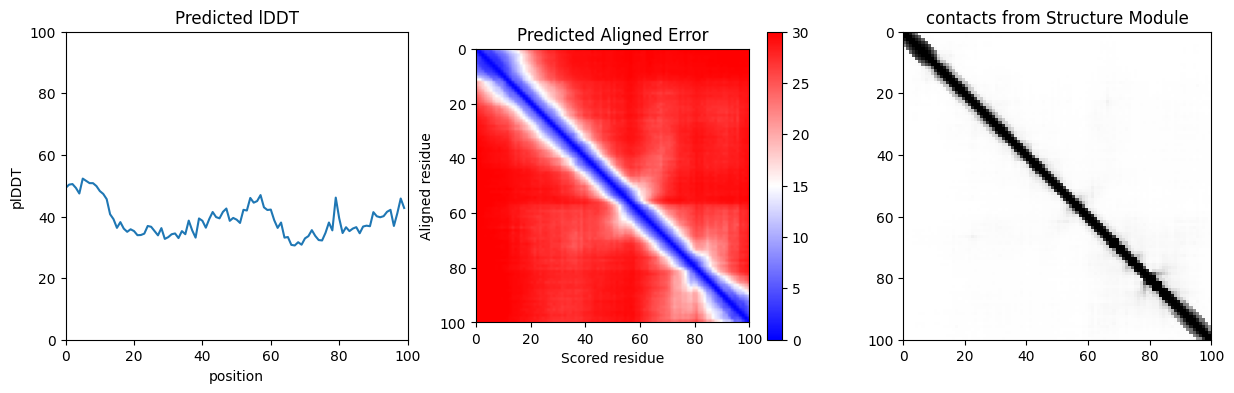

In [8]:
#@title plot confidence (optional)

dpi = 100 #@param {type:"integer"}

def plot_ticks(Ls):
  Ln = sum(Ls)
  L_prev = 0
  for L_i in Ls[:-1]:
    L = L_prev + L_i
    L_prev += L_i
    plt.plot([0,Ln],[L,L],color="black")
    plt.plot([L,L],[0,Ln],color="black")
  ticks = np.cumsum([0]+Ls)
  ticks = (ticks[1:] + ticks[:-1])/2
  plt.yticks(ticks,alphabet_list[:len(ticks)])

def plot_confidence(O, Ls=None, dpi=100):
  if "lm_contacts" in O:
    plt.figure(figsize=(20,4), dpi=dpi)
    plt.subplot(1,4,1)
  else:
    plt.figure(figsize=(15,4), dpi=dpi)
    plt.subplot(1,3,1)

  plt.title('Predicted lDDT')
  plt.plot(O["plddt"])
  if Ls is not None:
    L_prev = 0
    for L_i in Ls[:-1]:
      L = L_prev + L_i
      L_prev += L_i
      plt.plot([L,L],[0,100],color="black")
  plt.xlim(0,O["plddt"].shape[0])
  plt.ylim(0,100)
  plt.ylabel('plDDT')
  plt.xlabel('position')
  plt.subplot(1,4 if "lm_contacts" in O else 3,2)

  plt.title('Predicted Aligned Error')
  Ln = O["pae"].shape[0]
  plt.imshow(O["pae"],cmap="bwr",vmin=0,vmax=30,extent=(0, Ln, Ln, 0))
  if Ls is not None and len(Ls) > 1: plot_ticks(Ls)
  plt.colorbar()
  plt.xlabel('Scored residue')
  plt.ylabel('Aligned residue')

  if "lm_contacts" in O:
    plt.subplot(1,4,3)
    plt.title("contacts from LM")
    plt.imshow(O["lm_contacts"],cmap="Greys",vmin=0,vmax=1,extent=(0, Ln, Ln, 0))
    if Ls is not None and len(Ls) > 1: plot_ticks(Ls)
    plt.subplot(1,4,4)
  else:
    plt.subplot(1,3,3)
  plt.title("contacts from Structure Module")
  plt.imshow(O["sm_contacts"],cmap="Greys",vmin=0,vmax=1,extent=(0, Ln, Ln, 0))
  if Ls is not None and len(Ls) > 1: plot_ticks(Ls)
  return plt

plot_confidence(O, Ls=lengths, dpi=dpi)
plt.savefig(f'{prefix}.png',bbox_inches='tight')
plt.show()

In [9]:
#@title download predictions
from google.colab import files
archive = shutil.make_archive(str(Path(ID).resolve()), "zip", root_dir=ID)
files.download(archive)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>